In [1]:
import sys
import os
from pathlib import Path
sys.path.append(str(Path(os.getcwd()).parent))

In [2]:
import numpy as np

In [3]:
acc1 = 0
for i in range(20):
    file_path = f'../data/fidelity/noise_T1T2norst_SIC_1/opt_0_shots_2000000_{i}.npy'
    data = np.load(file_path)
    acc1 += np.sum(data)
acc1 = acc1/(20*2000000)
acc1

(0.8612746249999997+3.370609349083071e-20j)

In [4]:
acc2 = 0
for i in range(20):
    file_path = f'../data/fidelity/noise_T1T2norst_SIC_1/opt_1_shots_2000000_{i}.npy'
    data = np.load(file_path)
    acc2 += np.sum(data)
acc2 = acc2/(20*2000000)
acc2

(0.9076298249999998+1.6236683476488494e-19j)

In [5]:
acc3 = 0
for i in range(20):
    file_path = f'../data/fidelity/noise_T1T2norst_SIC_1/opt_2_shots_2000000_{i}.npy'
    data = np.load(file_path)
    acc3 += np.sum(data)
acc3 = acc3/(20*2000000)
acc3

(0.9559572999999998+1.4587006727882654e-20j)

Processing qubit counts for noiseless set:   0%|          | 0/1 [00:00<?, ?it/s]


 160000



 160000



 160000



 160000


...


 39060

 19520



 9760

 4880



 2440

 1220


Processing group sizes for noiseless set, qubit count 6: 100%|██████████| 17/17 [00:06<00:00,  2.52it/s]
Processing qubit counts for noiseless set: 100%|██████████| 1/1 [00:06<00:00,  6.74s/it]
/opt/anaconda3/envs/pennylane/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/envs/pennylane/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)



 600


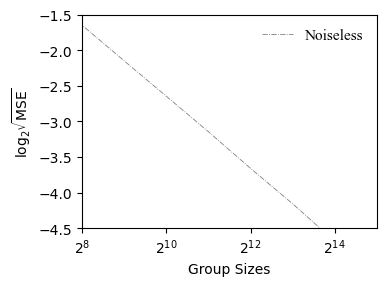

In [6]:
import os
import sys
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

# 参数设置
noises = ['T1T2norst']
sics = ['SIC_1']
opts = ['opt_0', 'opt_1', 'opt_2']
sets = [(noise, sic, opt) for noise in noises for sic in sics for opt in opts]
sets.append(('None', 'SIC_1', 'opt_2'))  # 添加 Noiseless
total_data_points_per_set = 2000000  # 每个 set 的数据点数
num_datasets = 20  # 数据集的数量
group_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384, 32768, 65536]
true_fidelity = 1
qubit_counts = [6]

# 单独处理 sets[3] 的计算
set_name_noiseless = sets[3]  # 提取 sets[3]
group_variances_noiseless = []  # 用于保存 Noiseless 的方差

for num_qubits in tqdm(qubit_counts, desc=f"Processing qubit counts for noiseless set"):
    for group_size in tqdm(group_sizes, desc=f"Processing group sizes for noiseless set, qubit count {num_qubits}"):
        a_values_noiseless = []
        for dataset_index in range(num_datasets):
            # 文件路径
            file_path = f'../data/fidelity/noise_{set_name_noiseless[0]}_{set_name_noiseless[1]}/{set_name_noiseless[2]}_shots_{total_data_points_per_set}_{dataset_index}.npy'
            
            # 确保文件存在，避免因缺失文件导致报错
            if not os.path.exists(file_path):
                print(f"File not found: {file_path}")
                continue
            
            data = np.load(file_path)
            
            # 根据 group_size 选择数据处理方式
            if group_size <= 64:
                num_a_values = 8000
            else:
                num_a_values = total_data_points_per_set // group_size
            
            for k in range(0, group_size * num_a_values, group_size):
                subset = data[k:k + group_size]
                a = np.mean(subset)
                a_values_noiseless.append(a)
        
        print('\n', len(a_values_noiseless))
        
        # 计算方差
        b_noiseless = np.mean([(a - true_fidelity) ** 2 for a in a_values_noiseless])
        group_variances_noiseless.append(np.log2(np.sqrt(b_noiseless)))

# 绘图部分
plt.figure(figsize=(4, 3))  # 定义图像大小
plt.plot(
    group_sizes, 
    group_variances_noiseless, 
    label='Noiseless', 
    linewidth=0.6, 
    linestyle='-.', 
    color='grey'
)

# 图形美化
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'Times New Roman',
})
plt.ylim(-4.5, -1.5)
plt.xlim(256, 32768)
plt.xscale('log', base=2)
plt.xlabel('Group Sizes')
plt.ylabel('$\\mathrm{log_2\\sqrt{MSE}}$')
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


In [7]:
len(group_variances_noiseless)

17

/opt/anaconda3/envs/pennylane/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/envs/pennylane/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


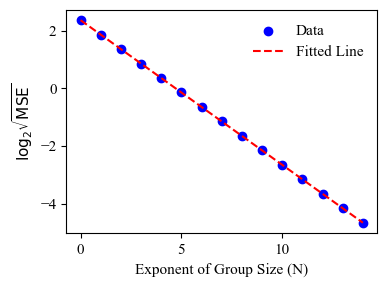

拟合的直线方程为: y = -0.5025 * N + 2.3704


In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 假设这里已经有 group_sizes 和 group_variances_noiseless 的数据

# 示例数据（假设这些是拟合数据）
group_size_exponents = np.array(range(15)) # 对应的 N 值
group_variances_noiseless = group_variances_noiseless[:15]  # 对应的方差值
# 将数据进行重塑，以便进行线性回归
X = group_size_exponents.reshape(-1, 1)  # 将 X 变为二维数组，适应 LinearRegression 输入
y = group_variances_noiseless

# 创建线性回归模型并拟合数据
# 检查是否有复数部分并取实部
X = np.real(X)
y = np.real(y)

# 创建线性回归模型并拟合数据
model = LinearRegression()
model.fit(X, y)

# 拟合后的直线的斜率和截距
slope = model.coef_[0]
intercept = model.intercept_

# 创建预测函数
def predict_variance(N):
    """
    根据给定的 N（即 log2(group_size)），返回预测的方差值。
    """
    return slope * N + intercept

# 绘制原始数据和拟合的直线
plt.figure(figsize=(4, 3))
plt.scatter(group_size_exponents, group_variances_noiseless, color='blue', label='Data')
plt.plot(group_size_exponents, model.predict(X), color='red', linestyle='--', label='Fitted Line')

# 设置图表样式
plt.xlabel('Exponent of Group Size (N)')
plt.ylabel('$\\mathrm{log_2\\sqrt{MSE}}$')
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# 打印拟合的方程
print(f"拟合的直线方程为: y = {slope:.4f} * N + {intercept:.4f}")


In [9]:
predict_variance(22)

-8.684309005597964